# 02 — First analysis: returns, dependence, and volatility

Read the frozen dataset from `dataset.ipynb`, verify it, and work through the evidence in small steps.
The default sample is **January 2000–September 2026**, using the download cutoff **13 November 2026**.
This notebook is fully offline and never modifies or re-fetches the working data.

1. Verify the saved data and review quality flags.
2. Summarise monthly excess returns and nominal cumulative performance.
3. Compare volatility and correlations across USD and EUR perspectives.
4. Screen for serial dependence, ARCH effects, and persistent predictors.
5. Record the first findings and the next estimation step.

These are descriptive checks and preliminary diagnostics. Correlation with a currency factor does
not establish that currency risk earns a premium; that requires the joint pricing-model estimation.

**Environment:** use your existing Miniconda **base** kernel. The first code cell records package versions. If statsmodels needs updating, run `%pip install --upgrade statsmodels==0.15.0` in the current kernel, then **Restart Kernel and Run All**. No custom kernel is required.

In [1]:
# Adjustable settings. To analyse a latest-data run, explicitly select its saved folder here.
SNAPSHOT = "data/fixed_2026-11-13/from_2000-01"
ANALYSIS_START = None  # e.g. "2008-03"; None keeps the saved beginning.
ANALYSIS_END = None    # e.g. "2020-12"; None keeps the saved end.
VOL_WINDOW = 12        # months
CORR_WINDOW = 36       # months
TEST_LAGS = 12         # Ljung–Box, ARCH, and maximum ADF lag

from pathlib import Path
from io import BytesIO
import hashlib
import importlib.metadata
import json
import os
import platform
import sys

ROOT = Path.cwd()
# Use the currently selected kernel (including Miniconda base); record its versions.
runtime_versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'matplotlib', 'statsmodels']}
print("Python:", sys.executable)
print("Packages:", runtime_versions)
from packaging.version import Version
if Version(runtime_versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Run %pip install --upgrade statsmodels==0.15.0 in this notebook, then Restart Kernel and Run All.")
loaded_statsmodels = sys.modules.get("statsmodels")
if loaded_statsmodels is not None and loaded_statsmodels.__version__ != runtime_versions["statsmodels"]:
    raise RuntimeError("statsmodels was updated in this environment. Restart Kernel and Run All to discard the old imports.")

os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import adfuller
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.18})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 30)
source = ROOT / SNAPSHOT
OUT = ROOT / "output" / "02_analysis" / source.parent.name / source.name
OUT.mkdir(parents=True, exist_ok=True)
COLORS = {"Hungary": "#b34c36", "World": "#235789", "US": "#34816d"}

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'matplotlib': '3.10.8', 'statsmodels': '0.15.0'}


## 1. Verify the input before interpreting it

Check the saved CSV checksums against the sealed manifest, the monthly calendar, and the USD/EUR
conversion identities. A damaged file or a missing internal month stops the analysis.

The EUR cash return remains the documented lagged one-month Euribor proxy. Its credit-risk and timing
differences from USD Treasury-bill cash affect comparisons of excess returns. The world portfolio is
the free Fama–French Developed market proxy. All stored returns are monthly log returns in decimals.

In [2]:
manifest = json.loads((source / "manifest.json").read_text())
if not manifest.get("sealed") or manifest.get("recipe_version") != 1:
    raise ValueError("Use a sealed dataset snapshot with recipe_version=1.")

def read_verified(name):
    raw = (source / name).read_bytes()
    if hashlib.sha256(raw).hexdigest() != manifest["exports"][name]:
        raise ValueError(f"Frozen data checksum mismatch: {name}")
    frame = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
    frame.index = pd.PeriodIndex(frame.index, freq="M", name="month")
    return frame

full_data = read_verified("dataset.csv")
inputs = read_verified("monthly_inputs.csv")
if list(full_data.columns) != manifest["variables"] or len(full_data) != manifest["observations"]:
    raise ValueError("Saved dimensions differ from the manifest.")
if str(full_data.index[0]) != manifest["working_first_month"] or str(full_data.index[-1]) != manifest["working_last_month"]:
    raise ValueError("Saved dates differ from the manifest.")
if not full_data.index.equals(pd.period_range(full_data.index[0], full_data.index[-1], freq="M")):
    raise ValueError("The working sample has a duplicate or missing month.")
if not np.isfinite(full_data.to_numpy()).all():
    raise ValueError("Non-finite data in the working sample.")
data = full_data.loc[ANALYSIS_START:ANALYSIS_END].copy()
if not (2 <= TEST_LAGS <= 24) or min(VOL_WINDOW, CORR_WINDOW) < 2:
    raise ValueError("Choose TEST_LAGS from 2 to 24 and rolling windows of at least 2 months.")
if len(data) < max(60, CORR_WINDOW, VOL_WINDOW, 4 * TEST_LAGS + 5):
    raise ValueError("Select a longer analysis window for the requested diagnostics.")
for market in ["hu", "world", "us"]:
    np.testing.assert_allclose(data[f"r_{market}_usd"] - data[f"r_{market}_eur"],
                               data["fx_eur_usd"], atol=1e-12, rtol=0)
    for currency, cash in [("usd", "rf_usd"), ("eur", "rf_eur_proxy")]:
        np.testing.assert_allclose(data[f"rx_{market}_{currency}"],
                                   data[f"r_{market}_{currency}"] - data[cash], atol=1e-12, rtol=0)

audit = pd.DataFrame([{
    "snapshot_mode": manifest["mode"], "download_cutoff": manifest["requested_end_date"],
    "first_month": str(data.index[0]), "last_month": str(data.index[-1]),
    "months": len(data), "missing_cells": int(data.isna().sum().sum()),
    "carried_US_inflation_months": int(data["flag_us_inflation_carried_lag2"].sum()),
}])
display(audit)
flagged = data.loc[data["flag_us_inflation_carried_lag2"].eq(1),
                   ["inflation_gap_usd_lag2_pp", "flag_us_inflation_carried_lag2"]]
display(flagged.rename_axis("flagged_month"))

,snapshot_mode,download_cutoff,first_month,last_month,months,missing_cells,carried_US_inflation_months
0,fixed,2026-11-13,2000-01,2026-09,321,0,1


,inflation_gap_usd_lag2_pp,flag_us_inflation_carried_lag2
flagged_month,,
2025-12,-1.202877,1


The flag identifies use of the last available annual US inflation report in the December 2025
conditioning variable, following the missing October 2025 CPI report. The raw CPI observation remains
missing; asset returns and FX are not filled. Keep the flag for later sensitivity analysis.

## 2. Summarise the return distributions

Equities below are **excess** log returns. FX is the log change in the forint's value in the investor's
currency; positive means forint appreciation. Monthly means, standard deviations, and extremes are in
percent. Skewness and excess kurtosis describe asymmetry and tails; normal excess kurtosis is zero.
The annualised standard deviation is `monthly standard deviation × sqrt(12)`, a conventional scale
comparison rather than an estimate of a full-year variance allowing for serial correlation.

In [3]:
series = {}
for currency in ["usd", "eur"]:
    for market, label in [("hu", "Hungary"), ("world", "World"), ("us", "US")]:
        series[(currency.upper(), label)] = data[f"rx_{market}_{currency}"]
    series[(currency.upper(), "HUF FX")] = data[f"fx_huf_{currency}"]
returns = pd.DataFrame(series)
descriptive = pd.DataFrame({
    "n": returns.count(), "mean_monthly_pct": returns.mean() * 100,
    "sd_monthly_pct": returns.std() * 100, "sd_annualised_pct": returns.std() * np.sqrt(12) * 100,
    "skewness": returns.skew(), "excess_kurtosis": returns.kurt(),
    "min_monthly_pct": returns.min() * 100, "max_monthly_pct": returns.max() * 100,
})
descriptive.index.names = ["perspective", "series"]
display(descriptive.round(3))

n  mean_monthly_pct  sd_monthly_pct  sd_annualised_pct  \
perspective series                                                              
USD         Hungary  321             0.639           8.610             29.827   
            World    321             0.424           4.520             15.659   
            US       321             0.520           4.551             15.767   
            HUF FX   321            -0.075           3.854             13.350   
EUR         Hungary  321             0.630           7.488             25.941   
            World    321             0.415           4.128             14.300   
            US       321             0.511           4.528             15.685   
            HUF FX   321            -0.113           2.164              7.495   

                     skewness  excess_kurtosis  min_monthly_pct  \
perspective series                                                
USD         Hungary    -1.112            5.034          -52.340   
            World      -0.805            1.924          -21.684   
            US         -0.648            1.101          -18.858   
            HUF FX     -1.007            3.854          -19.700   
EUR         Hungary    -0.902            3.537          -41.221   
            World      -0.710            0.979          -14.444   
            US         -0.578            0.786          -14.274   
            HUF FX     -0.695            3.478          -11.459   

                     max_monthly_pct  
perspective series                    
USD         Hungary           23.427  
            World             12.521  
            US                12.751  
            HUF FX            11.592  
EUR         Hungary           21.134  
            World             10.956  
            US                13.524  
            HUF FX             6.796

## 3. View nominal cumulative performance

Use the **total** return columns here, including dividends and before subtracting cash. Start each
portfolio at 100 immediately before the first selected month. The logarithmic vertical scale makes
proportional changes comparable. Currency conversion is applied to the same portfolios; the EUR
version is unhedged. These are realised historical paths, not estimated risk premiums.

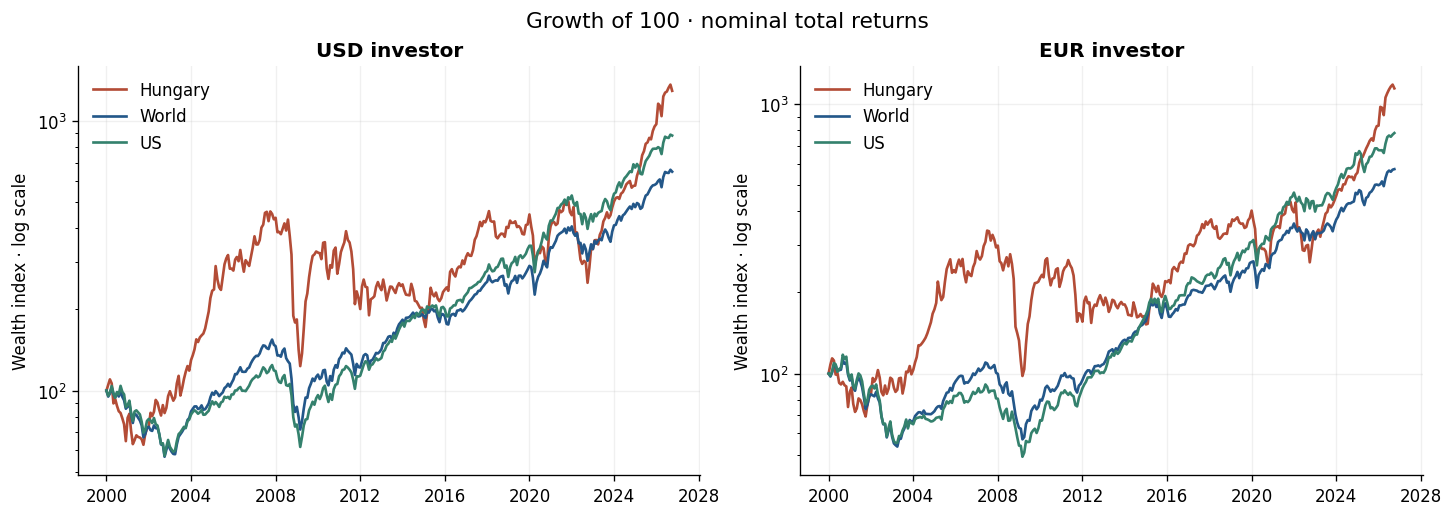

In [4]:
def save_plot(name):
    plt.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

dates = data.index.to_timestamp("M")
base_date = (data.index[0] - 1).to_timestamp("M")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
for ax, currency in zip(axes, ["usd", "eur"]):
    for market, label in [("hu", "Hungary"), ("world", "World"), ("us", "US")]:
        wealth = np.r_[100.0, 100 * np.exp(data[f"r_{market}_{currency}"].cumsum())]
        ax.plot(pd.DatetimeIndex([base_date]).append(dates), wealth, label=label, color=COLORS[label], lw=1.6)
    ax.set(title=f"{currency.upper()} investor", ylabel="Wealth index · log scale", yscale="log")
    ax.legend(frameon=False)
fig.suptitle("Growth of 100 · nominal total returns", fontsize=13)
save_plot("01_cumulative_wealth.png")

## 4. Inspect changes in volatility

Rolling windows use the current and preceding observations only. A rolling sample standard deviation
is descriptive; it is not the model's conditional covariance forecast. Look for clustered high-risk
periods and differences between investor perspectives.

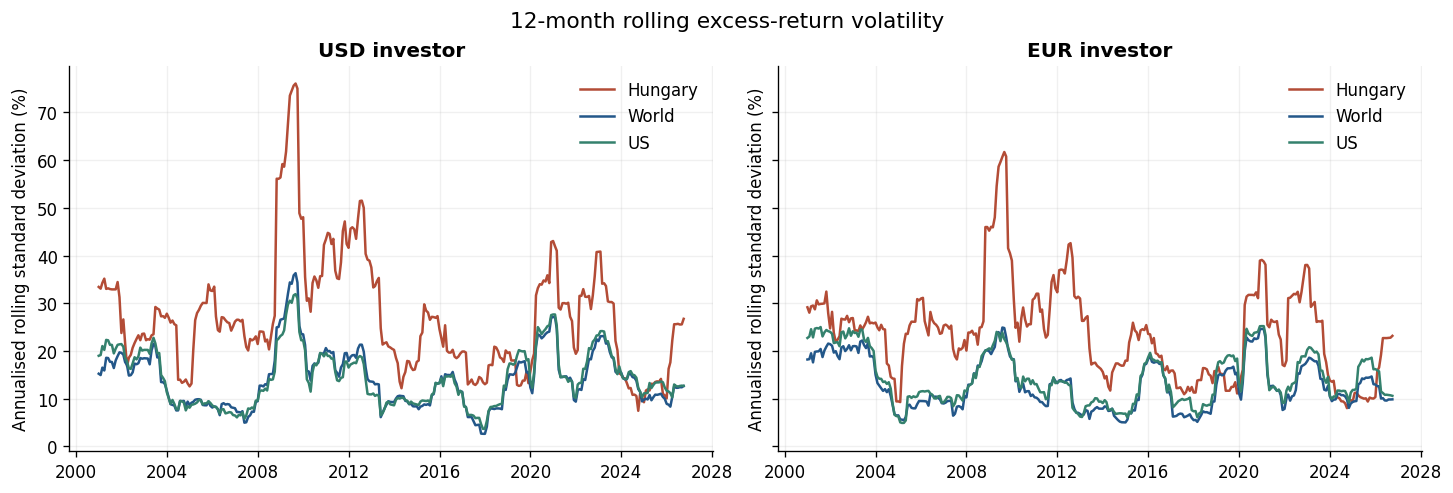

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
for ax, currency in zip(axes, ["usd", "eur"]):
    for market, label in [("hu", "Hungary"), ("world", "World"), ("us", "US")]:
        volatility = data[f"rx_{market}_{currency}"].rolling(VOL_WINDOW, min_periods=VOL_WINDOW).std() * np.sqrt(12) * 100
        ax.plot(dates, volatility, label=label, color=COLORS[label], lw=1.5)
    ax.set(title=f"{currency.upper()} investor", ylabel="Annualised rolling standard deviation (%)")
    ax.legend(frameon=False)
fig.suptitle(f"{VOL_WINDOW}-month rolling excess-return volatility", fontsize=13)
save_plot("02_rolling_volatility.png")

## 5. Examine correlations and their stability

First inspect full-sample contemporaneous correlations, then rolling correlations of Hungarian
excess returns with world excess returns and the HUF currency factor. The US and world portfolios
overlap substantially. Hungarian foreign-currency returns also mechanically include the FX change.
Neither a high correlation nor a change in correlation establishes that a source of risk is priced.

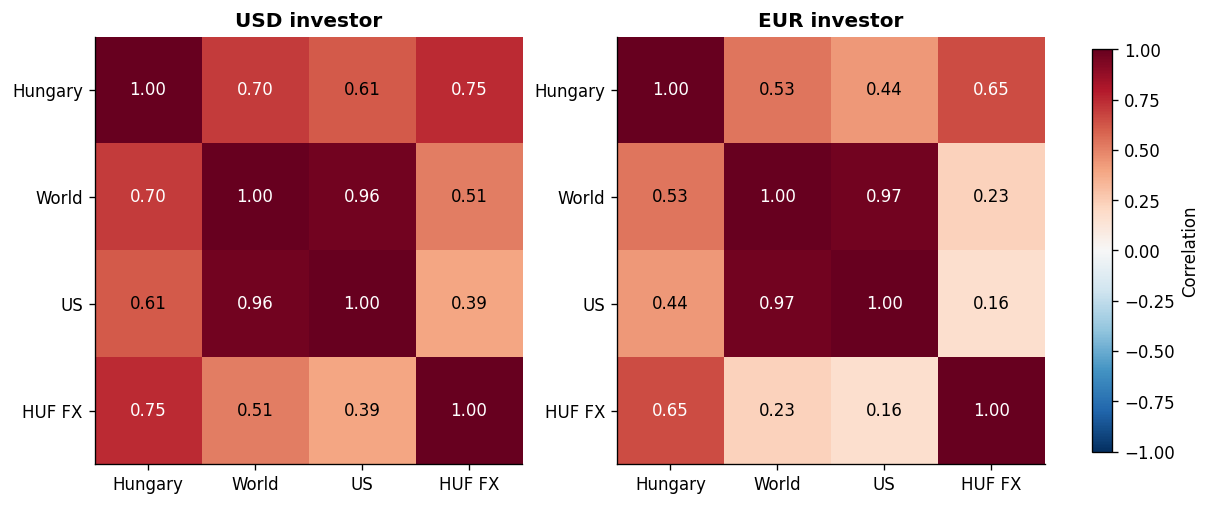

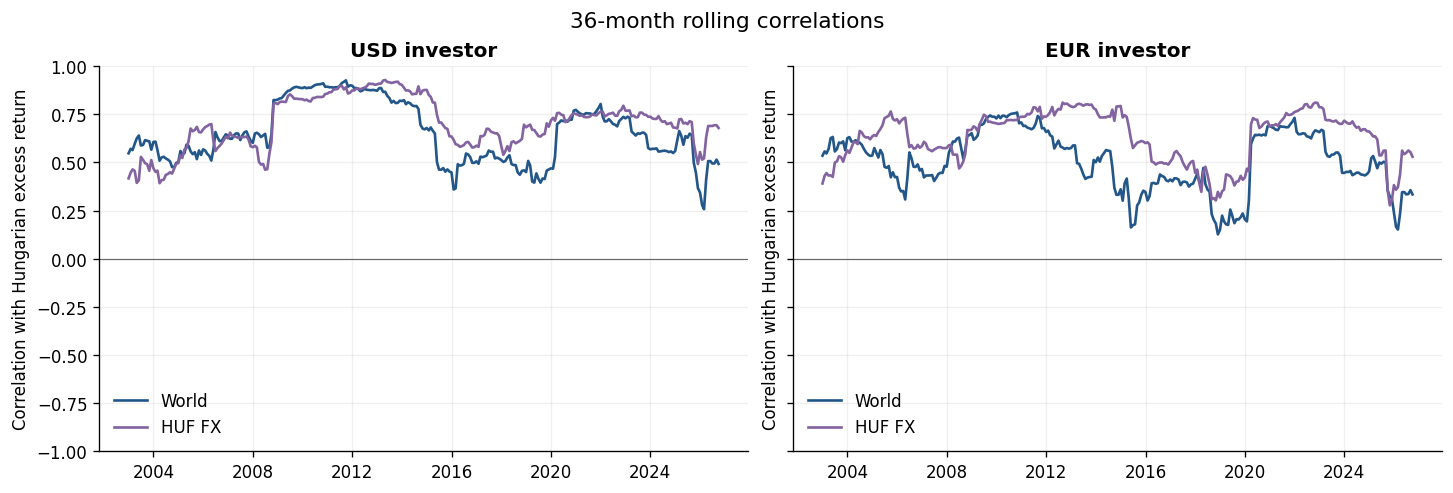

In [6]:
correlations = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), layout="constrained")
for ax, currency in zip(axes, ["USD", "EUR"]):
    corr = returns[currency].corr()
    correlations[currency] = corr
    image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(xticks=range(4), yticks=range(4), xticklabels=corr.columns,
           yticklabels=corr.index, title=f"{currency} investor")
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                    color="white" if abs(corr.iloc[i, j]) > 0.65 else "black", fontsize=10)
fig.colorbar(image, ax=axes, shrink=0.8, label="Correlation")
save_plot("03_correlations.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
for ax, currency in zip(axes, ["usd", "eur"]):
    hu = data[f"rx_hu_{currency}"]
    for other, label, color in [(f"rx_world_{currency}", "World", COLORS["World"]),
                                (f"fx_huf_{currency}", "HUF FX", "#8364a0")]:
        ax.plot(dates, hu.rolling(CORR_WINDOW, min_periods=CORR_WINDOW).corr(data[other]),
                label=label, color=color, lw=1.6)
    ax.axhline(0, color="#666666", lw=0.7)
    ax.set(title=f"{currency.upper()} investor", ylabel="Correlation with Hungarian excess return", ylim=(-1, 1))
    ax.legend(frameon=False)
fig.suptitle(f"{CORR_WINDOW}-month rolling correlations", fontsize=13)
save_plot("04_rolling_correlations.png")

## 6. Screen the time-series properties

For each series, fit an **AR(1) mean with an intercept** as a preliminary diagnostic. It is not an
asset-pricing model. Then report:

| Diagnostic | Null hypothesis | Role here |
|---|---|---|
| Ljung–Box on original returns | No autocorrelation through the selected lag | Screen the mean dynamics |
| Ljung–Box on AR(1) residuals | No residual autocorrelation through that lag | Check whether a simple mean is adequate |
| ARCH LM on AR(1) residuals | No ARCH effects through that lag | Screen for predictable squared shocks |
| ADF on original returns | A unit root, with a constant | Screen persistence; rejection does not prove full stationarity |

ARCH uses a two-parameter mean degrees-of-freedom adjustment; residual Ljung–Box uses one AR lag.
ADF selects lags by AIC up to `TEST_LAGS`. These are exploratory asymptotic p-values, without
multiple-testing adjustment. Unmodelled mean dynamics, structural changes, and heavy tails can affect
them. Revisit residual diagnostics after fitting the joint model. Do not select a GARCH specification
solely from these screens.

Methods: [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html),
[ARCH LM](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_arch.html),
[ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html).

In [7]:
rows = []
for (currency, label), s in series.items():
    ar_data = pd.concat([s.rename("y"), s.shift(1).rename("lag1")], axis=1).dropna()
    ar_fit = OLS(ar_data["y"], add_constant(ar_data[["lag1"]], has_constant="add")).fit()
    rows.append({
        "perspective": currency, "series": label, "n": len(s),
        "AR1_slope": ar_fit.params["lag1"],
        "LB_return_p": acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True)["lb_pvalue"].iloc[0],
        "LB_AR1_residual_p": acorr_ljungbox(ar_fit.resid, lags=[TEST_LAGS], model_df=1, return_df=True)["lb_pvalue"].iloc[0],
        "ARCH_LM_p": het_arch(ar_fit.resid, nlags=TEST_LAGS, ddof=2, result_object=False)[1],
        "ADF_return_p": adfuller(s, maxlag=TEST_LAGS, regression="c", autolag="AIC", result_object=False)[1],
    })
diagnostics = pd.DataFrame(rows).set_index(["perspective", "series"])
display(diagnostics.round(4))

n  AR1_slope  LB_return_p  LB_AR1_residual_p  \
perspective series                                                    
USD         Hungary  321     0.1088       0.4149             0.5413   
            World    321     0.0786       0.3599             0.4233   
            US       321     0.0403       0.2850             0.2326   
            HUF FX   321     0.0079       0.1839             0.1371   
EUR         Hungary  321     0.1218       0.5401             0.6618   
            World    321     0.1077       0.2588             0.6184   
            US       321     0.0928       0.1044             0.2844   
            HUF FX   321     0.0095       0.0070             0.0046   

                     ARCH_LM_p  ADF_return_p  
perspective series                            
USD         Hungary     0.1328        0.0000  
            World       0.0001        0.0000  
            US          0.0000        0.0000  
            HUF FX      0.0000        0.0000  
EUR         Hungary     0.0858        0.0000  
            World       0.0012        0.0000  
            US          0.0030        0.0003  
            HUF FX      0.0000        0.0000

## 7. Inspect the conditioning variables

These are already lagged in `dataset.csv`: do not shift them again. Inspect persistence and the
rank of the candidate instrument sets before estimation. ADF results are only a screen: inflation
differentials and credit spreads can be persistent or affected by breaks. Regime and quality flags
are not subjected to unit-root tests.

The global set contains an intercept and three US financial predictors. Each perspective's extended
set adds its inflation gap and the regime indicator. This is a candidate conditioning design for
discussion; it does not imply that every risk price must use the same predictors.

In [8]:
global_z = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
predictor_columns = global_z + ["inflation_gap_usd_lag2_pp", "inflation_gap_eur_lag2_pp"]
predictors = pd.DataFrame({"mean_pp": data[predictor_columns].mean(),
                           "sd_pp": data[predictor_columns].std(),
                           "lag1_correlation": data[predictor_columns].apply(lambda s: s.autocorr(1))})
predictors["ADF_p"] = [adfuller(data[c], maxlag=TEST_LAGS, regression="c", autolag="AIC", result_object=False)[1]
                        for c in predictor_columns]
predictors.index.name = "predictor"
display(predictors.round(4))

rank_rows = []
for name, columns in [("Global", global_z),
                      ("USD extended", global_z + ["inflation_gap_usd_lag2_pp", "floating_regime_known"]),
                      ("EUR extended", global_z + ["inflation_gap_eur_lag2_pp", "floating_regime_known"])]:
    z = data[columns]
    varying = z.columns[z.std().gt(0)]
    matrix = add_constant((z[varying] - z[varying].mean()) / z[varying].std(), has_constant="add")
    rank_rows.append({"set": name, "columns_with_intercept": matrix.shape[1],
                      "rank": np.linalg.matrix_rank(matrix),
                      "standardised_condition_number": np.linalg.cond(matrix),
                      "constant_columns_excluded": ", ".join(z.columns.difference(varying)) or "none"})
instrument_rank = pd.DataFrame(rank_rows).set_index("set")
display(instrument_rank.round(3))

,mean_pp,sd_pp,lag1_correlation,ADF_p
predictor,,,,
short_rate_change_lag1_pp,-0.0042,0.1877,0.5490,0.0000
term_spread_change_lag1_pp,-0.0000,0.2360,0.3073,0.0000
credit_spread_lag1_pp,0.9906,0.3993,0.9580,0.0005
inflation_gap_usd_lag2_pp,-2.6005,3.7389,0.9786,0.1076
inflation_gap_eur_lag2_pp,-3.0522,3.2484,0.9778,0.1088


,columns_with_intercept,rank,standardised_condition_number,constant_columns_excluded
set,,,,
Global,4,4,1.792,none
USD extended,6,6,1.834,none
EUR extended,6,6,1.820,none


## 8. First findings and next step

Read this comparison together with the plots and diagnostics. The mean is a realised sample mean,
not the model-implied expected premium. The EUR cash proxy and the mechanical FX conversion remain
relevant to interpretation. At this stage, we have not tested whether local or currency risk is priced.

In [9]:
comparison = pd.DataFrame(index=["USD", "EUR"])
for currency in comparison.index:
    c = currency.lower()
    hu = data[f"rx_hu_{c}"]
    comparison.loc[currency, "HU_mean_monthly_log_pct"] = hu.mean() * 100
    comparison.loc[currency, "HU_sd_annualised_pct"] = hu.std() * np.sqrt(12) * 100
    comparison.loc[currency, "HU_world_correlation"] = hu.corr(data[f"rx_world_{c}"])
    comparison.loc[currency, "HU_FX_correlation"] = hu.corr(data[f"fx_huf_{c}"])
    comparison.loc[currency, "HU_ARCH_LM_p"] = diagnostics.loc[(currency, "Hungary"), "ARCH_LM_p"]
comparison.index.name = "perspective"
display(comparison.round(4))

dependent = [f"{currency} {label}" for (currency, label), row in diagnostics.iterrows()
             if row["LB_AR1_residual_p"] < 0.05]
inflation_adf = predictors.loc[["inflation_gap_usd_lag2_pp", "inflation_gap_eur_lag2_pp"], "ADF_p"]
display(Markdown(
    f"**Reading this run:**\n\n"
    f"- Hungarian annualised excess-return standard deviation: "
    f"**{comparison.loc['USD', 'HU_sd_annualised_pct']:.1f}% in USD**, "
    f"**{comparison.loc['EUR', 'HU_sd_annualised_pct']:.1f}% in EUR**.\n"
    f"- Series retaining residual autocorrelation at a nominal 5% level after AR(1): "
    f"**{', '.join(dependent) or 'none'}**. Revisit these mean dynamics before volatility modelling.\n"
    f"- Hungarian ARCH-screen p-values: USD **{comparison.loc['USD', 'HU_ARCH_LM_p']:.3f}**, "
    f"EUR **{comparison.loc['EUR', 'HU_ARCH_LM_p']:.3f}**. Compare these with the world, US, "
    f"and FX results; evidence can differ across series and lag choices.\n"
    f"- Inflation-gap ADF p-values: USD **{inflation_adf.iloc[0]:.3f}**, "
    f"EUR **{inflation_adf.iloc[1]:.3f}**. If the unit-root null is not rejected, investigate "
    f"persistence and breaks before treating these predictors as stationary. "
    f"Do not automatically difference them solely to obtain a smaller p-value.\n\n"
    f"These screens guide specification checks; they do not establish priced currency or local risk."
))

tables = {"audit.csv": audit, "descriptive.csv": descriptive, "diagnostics.csv": diagnostics,
          "predictors.csv": predictors, "instrument_rank.csv": instrument_rank,
          "comparison.csv": comparison}
for name, table in tables.items():
    table.to_csv(OUT / name, float_format="%.17g", lineterminator="\n")
for currency, corr in correlations.items():
    corr.to_csv(OUT / f"correlations_{currency.lower()}.csv", float_format="%.17g", lineterminator="\n")
metadata = {
    "source_snapshot": SNAPSHOT, "source_dataset_sha256": manifest["exports"]["dataset.csv"],
    "analysis_start": str(data.index[0]), "analysis_end": str(data.index[-1]), "observations": len(data),
    "settings": {"VOL_WINDOW": VOL_WINDOW, "CORR_WINDOW": CORR_WINDOW, "TEST_LAGS": TEST_LAGS},
    "python": platform.python_version(), "packages": {p: importlib.metadata.version(p)
        for p in ["numpy", "pandas", "matplotlib", "scipy", "statsmodels"]},
}
(OUT / "analysis_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True) + "\n")
display(Markdown(
    f"**Completed:** {len(data)} months, {data.index[0]}–{data.index[-1]}. "
    f"Tables and four figures are saved in `{OUT.relative_to(ROOT)}`.\n\n"
    "**Next estimation notebook:** fit a joint world/local pricing system with constant risk prices "
    "and a parsimonious conditional covariance process, then add currency pricing restrictions. "
    "Use the same sample for both perspectives and revisit residual adequacy before adding "
    "time-varying risk prices. A conventional return regression alone does not test the paper's "
    "covariance-based pricing restrictions."
))

,HU_mean_monthly_log_pct,HU_sd_annualised_pct,HU_world_correlation,HU_FX_correlation,HU_ARCH_LM_p
perspective,,,,,
USD,0.639,29.8271,0.7001,0.7464,0.1328
EUR,0.630,25.9405,0.5345,0.6519,0.0858


**Reading this run:**

- Hungarian annualised excess-return standard deviation: **29.8% in USD**, **25.9% in EUR**.
- Series retaining residual autocorrelation at a nominal 5% level after AR(1): **EUR HUF FX**. Revisit these mean dynamics before volatility modelling.
- Hungarian ARCH-screen p-values: USD **0.133**, EUR **0.086**. Compare these with the world, US, and FX results; evidence can differ across series and lag choices.
- Inflation-gap ADF p-values: USD **0.108**, EUR **0.109**. If the unit-root null is not rejected, investigate persistence and breaks before treating these predictors as stationary. Do not automatically difference them solely to obtain a smaller p-value.

These screens guide specification checks; they do not establish priced currency or local risk.

**Completed:** 321 months, 2000-01–2026-09. Tables and four figures are saved in `output/02_analysis/fixed_2026-11-13/from_2000-01`.

**Next estimation notebook:** fit a joint world/local pricing system with constant risk prices and a parsimonious conditional covariance process, then add currency pricing restrictions. Use the same sample for both perspectives and revisit residual adequacy before adding time-varying risk prices. A conventional return regression alone does not test the paper's covariance-based pricing restrictions.